In [1]:
import pandas as pd 
import numpy as np
import ot
import itertools
import seaborn as sns
import matplotlib.pyplot as plt

# SAM-Med3D

In [2]:
df_feats = pd.read_csv("../../local/output/combined_data_sammed.csv")
# Assume df_feats has 'client' column and 'Feature1'..'Feature384'
features_cols = [f'Feature{i}' for i in range(1, 385)]

# Get unique cohorts
cohorts = df_feats['cohort'].unique()

# Prepare results list
results = []

In [3]:
# Compute OT distance for each pair
for cohort1, cohort2 in itertools.combinations(cohorts, 2):
    print(f'Computing distance between {cohort1} and {cohort2}')
    X = df_feats[df_feats['cohort'] == cohort1][features_cols].to_numpy()
    Y = df_feats[df_feats['cohort'] == cohort2][features_cols].to_numpy()
    
    # Uniform weights
    a = np.ones((X.shape[0],)) / X.shape[0]
    b = np.ones((Y.shape[0],)) / Y.shape[0]
    
    # Cost matrix (squared Euclidean distance)
    M = ot.dist(X, Y, metric='euclidean')**2
    
    # Wasserstein-2 distance
    w2 = np.sqrt(ot.emd2(a, b, M))
    
    results.append({'pair': f'{cohort1}_{cohort2}', 'distance': w2})

Computing distance between ADNI and AIBL
Computing distance between ADNI and OASIS3
Computing distance between ADNI and OASIS4
Computing distance between ADNI and BrainLAT
Computing distance between ADNI and NigerianBrain
Computing distance between AIBL and OASIS3
Computing distance between AIBL and OASIS4
Computing distance between AIBL and BrainLAT
Computing distance between AIBL and NigerianBrain
Computing distance between OASIS3 and OASIS4
Computing distance between OASIS3 and BrainLAT
Computing distance between OASIS3 and NigerianBrain
Computing distance between OASIS4 and BrainLAT
Computing distance between OASIS4 and NigerianBrain
Computing distance between BrainLAT and NigerianBrain


In [4]:
df_results = pd.DataFrame(results)
distance_matrix = pd.DataFrame(0, index=cohorts, columns=cohorts, dtype=float)

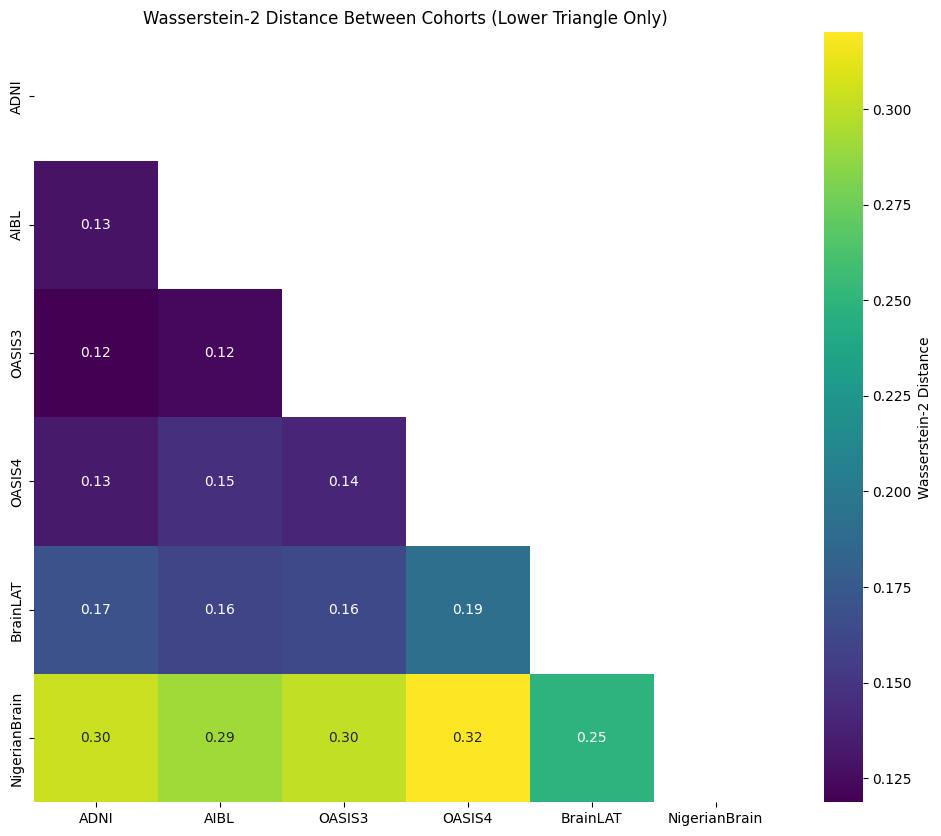

In [5]:
for row in results:
    c1, c2 = row['pair'].split('_')
    distance_matrix.loc[c1, c2] = row['distance']
    distance_matrix.loc[c2, c1] = row['distance']  # symmetric

mask = np.triu(np.ones_like(distance_matrix, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis',
            mask=mask, cbar_kws={'label': 'Wasserstein-2 Distance'})
plt.title('Wasserstein-2 Distance Between Cohorts (Lower Triangle Only)')
plt.show()


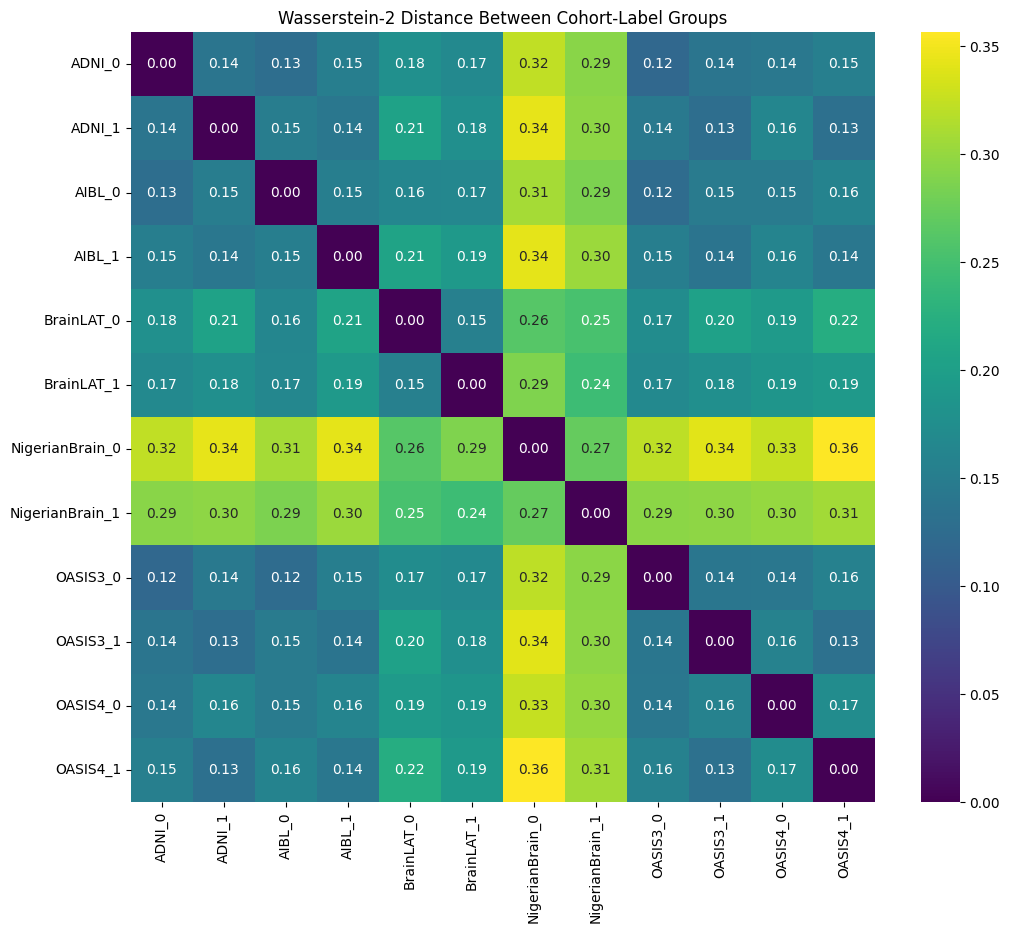

In [6]:
# Suppose 'distance_matrix' is already built with labels like 'ClientA_CN', 'ClientB_AD'

# Get unique (cohort, label) groups
groups = df_feats.groupby(['cohort', 'label'])

group_keys = list(groups.groups.keys())  # list of tuples (cohort, label)

results = []

# Compute Wasserstein-2 distance between all pairs of groups
for (c1, l1), (c2, l2) in itertools.combinations(group_keys, 2):
    X = groups.get_group((c1, l1))[features_cols].to_numpy()
    Y = groups.get_group((c2, l2))[features_cols].to_numpy()
    
    # Uniform weights
    a = np.ones((X.shape[0],)) / X.shape[0]
    b = np.ones((Y.shape[0],)) / Y.shape[0]
    
    # Cost matrix (squared Euclidean)
    M = ot.dist(X, Y, metric='euclidean')**2
    
    # Wasserstein-2 distance
    w2 = np.sqrt(ot.emd2(a, b, M))
    
    results.append({
        'pair': f'{c1}_{l1}-{c2}_{l2}',
        'distance': w2
    })

# Convert to DataFrame and save

# Convert to DataFrame and save
df_results = pd.DataFrame(results)

# Optional: create a heatmap
# Build a square distance matrix
all_keys = [f'{c}_{l}' for c, l in group_keys]
distance_matrix = pd.DataFrame(0, index=all_keys, columns=all_keys, dtype=float)

for row in results:
    g1, g2 = row['pair'].split('-')
    distance_matrix.loc[g1, g2] = row['distance']
    distance_matrix.loc[g2, g1] = row['distance']  # symmetric

plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis')
plt.title('Wasserstein-2 Distance Between Cohort-Label Groups')
plt.show()

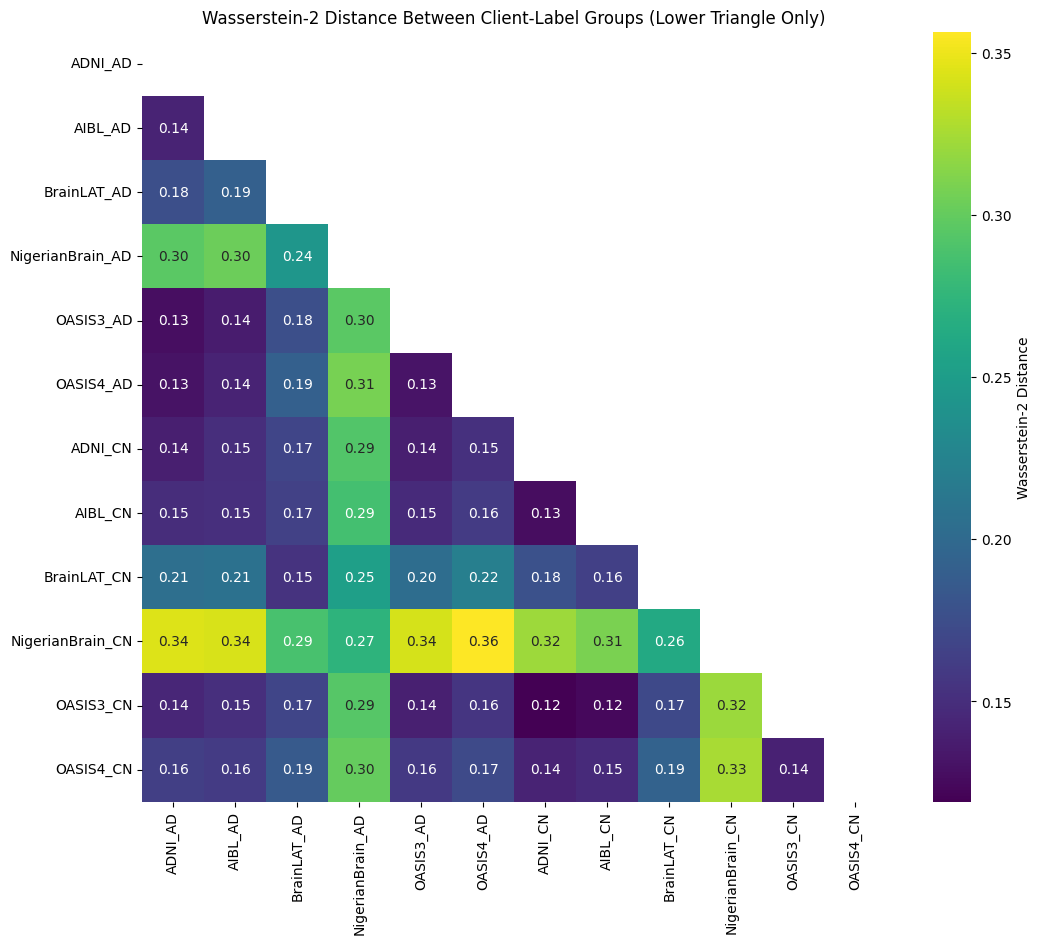

In [7]:
# Map label numbers to class names
label_map = {0: 'CN', 1: 'AD'}

# Build group keys with class names
all_keys = [f'{c}_{label_map[l]}' for c, l in group_keys]

# Order keys: all CN first, then all AD
all_keys_sorted = sorted(all_keys, key=lambda x: x.split('_')[-1])

# Build a square distance matrix
distance_matrix = pd.DataFrame(0, index=all_keys_sorted, columns=all_keys_sorted, dtype=float)

for row in results:
    g1, g2 = row['pair'].split('-')
    # Replace numeric labels with class names
    g1_name = f'{g1.split("_")[0]}_{label_map[int(g1.split("_")[1])]}'
    g2_name = f'{g2.split("_")[0]}_{label_map[int(g2.split("_")[1])]}'
    
    distance_matrix.loc[g1_name, g2_name] = row['distance']
    distance_matrix.loc[g2_name, g1_name] = row['distance']  # symmetric

# Create a mask for the upper triangle
mask = np.triu(np.ones_like(distance_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis',
            mask=mask, cbar_kws={'label': 'Wasserstein-2 Distance'})
plt.title('Wasserstein-2 Distance Between Client-Label Groups (Lower Triangle Only)')
plt.show()

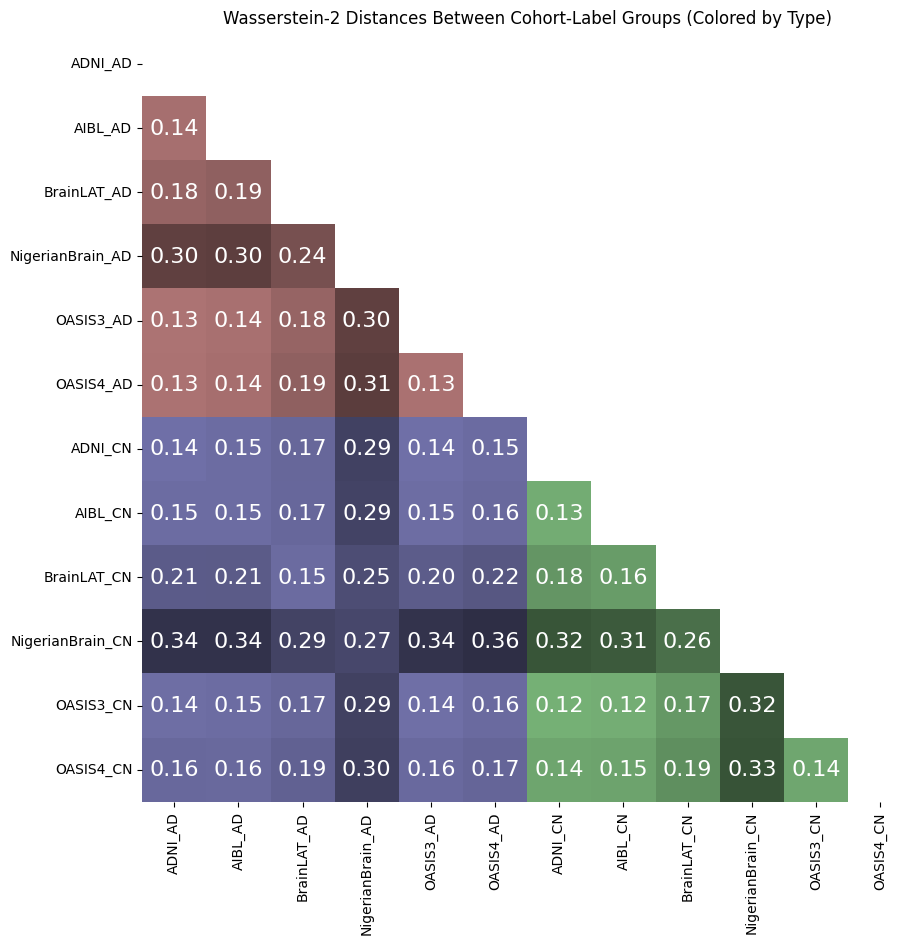

In [10]:
# Suppose 'distance_matrix' is already built with labels like 'ClientA_CN', 'ClientB_AD'
labels = distance_matrix.index.tolist()

# Extract class names from group keys
classes = [lbl.split('_')[-1] for lbl in labels]

# Create a color matrix
color_matrix = np.empty(distance_matrix.shape, dtype=object)

# Define base colors for each comparison type
color_map = {
    'CN_CN': np.array([0.6, 0.9, 0.6]),  # light green
    'AD_AD': np.array([0.9, 0.6, 0.6]),  # light red
    'CN_AD': np.array([0.6, 0.6, 0.9])   # light blue
}

# Normalize distances for intensity (0 = min, 1 = max)
dist_min = distance_matrix.values.min()
dist_max = distance_matrix.values.max()
norm_dist = (distance_matrix.values - dist_min) / (dist_max - dist_min + 1e-8)

for i, cls_i in enumerate(classes):
    for j, cls_j in enumerate(classes):
        if cls_i == 'CN' and cls_j == 'CN':
            base_color = color_map['CN_CN']
        elif cls_i == 'AD' and cls_j == 'AD':
            base_color = color_map['AD_AD']
        else:
            base_color = color_map['CN_AD']
      
        # Invert intensity: darker = higher distance
        intensity = 1 - norm_dist[i, j]
        # scale base color
        color_matrix[i, j] = base_color * (0.3 + 0.7 * intensity)

# Mask upper triangle
mask = np.triu(np.ones_like(distance_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", mask=mask,
            cmap=None, cbar=False, square=True,
            linewidths=.5, linecolor='white',
            annot_kws={"color": "white", "size": 16})

# Apply custom colors using facecolors
for i in range(len(labels)):
    for j in range(len(labels)):
        if mask[i,j]:
            continue
        plt.gca().add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color=color_matrix[i, j], lw=0))

plt.xticks(np.arange(len(labels))+0.5, labels, rotation=90)
plt.yticks(np.arange(len(labels))+0.5, labels, rotation=0)
plt.title('Wasserstein-2 Distances Between Cohort-Label Groups (Colored by Type)')
plt.show()

# BrainIAC

In [11]:
df_feats = pd.read_csv("../../local/output/combined_data_brainiac.csv")
# Assume df_feats has 'cohort' column and 'Feature1'..'Feature768'
features_cols = [f'Feature{i}' for i in range(1, 769)]

# Get unique cohorts
cohorts = df_feats['cohort'].unique()

# Prepare results list
results = []

In [12]:
# Compute OT distance for each pair
for cohort1, cohort2 in itertools.combinations(cohorts, 2):
    print(f'Computing distance between {cohort1} and {cohort2}')
    X = df_feats[df_feats['cohort'] == cohort1][features_cols].to_numpy()
    Y = df_feats[df_feats['cohort'] == cohort2][features_cols].to_numpy()
    
    # Uniform weights
    a = np.ones((X.shape[0],)) / X.shape[0]
    b = np.ones((Y.shape[0],)) / Y.shape[0]
    
    # Cost matrix (squared Euclidean distance)
    M = ot.dist(X, Y, metric='euclidean')**2
    
    # Wasserstein-2 distance
    w2 = np.sqrt(ot.emd2(a, b, M))
    
    results.append({'pair': f'{cohort1}_{cohort2}', 'distance': w2})

Computing distance between ADNI and AIBL
Computing distance between ADNI and OASIS3
Computing distance between ADNI and OASIS4
Computing distance between ADNI and BrainLAT
Computing distance between ADNI and NigerianBrain
Computing distance between AIBL and OASIS3
Computing distance between AIBL and OASIS4
Computing distance between AIBL and BrainLAT
Computing distance between AIBL and NigerianBrain
Computing distance between OASIS3 and OASIS4
Computing distance between OASIS3 and BrainLAT
Computing distance between OASIS3 and NigerianBrain
Computing distance between OASIS4 and BrainLAT
Computing distance between OASIS4 and NigerianBrain
Computing distance between BrainLAT and NigerianBrain


In [13]:
df_results = pd.DataFrame(results)
distance_matrix = pd.DataFrame(0, index=cohorts, columns=cohorts, dtype=float)

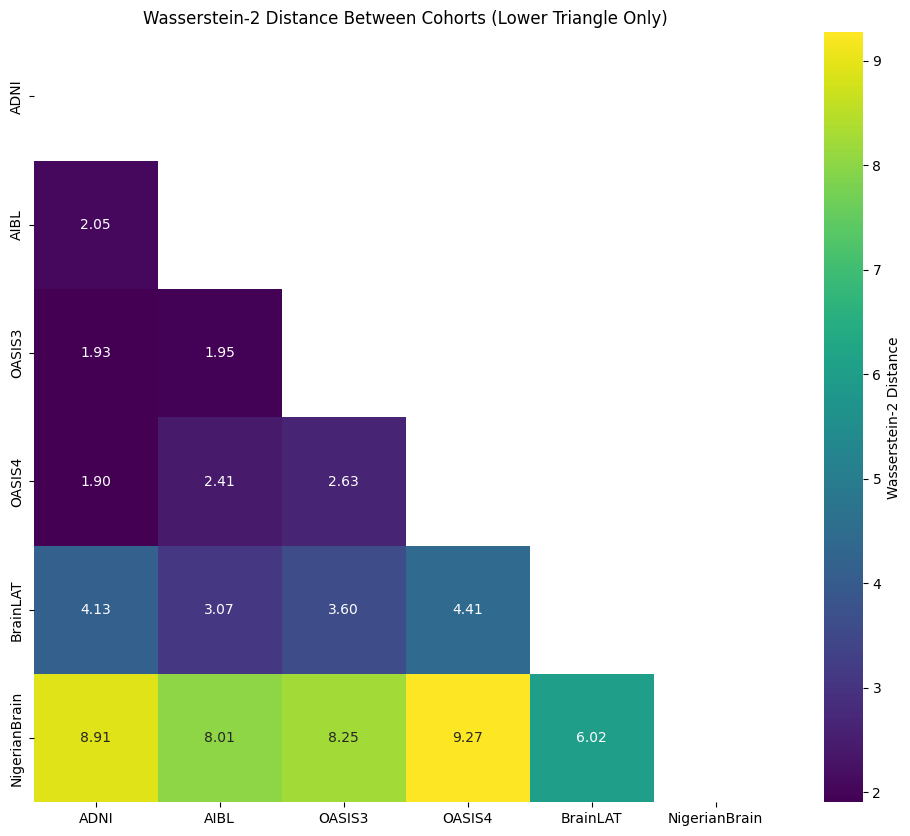

In [14]:
for row in results:
    c1, c2 = row['pair'].split('_')
    distance_matrix.loc[c1, c2] = row['distance']
    distance_matrix.loc[c2, c1] = row['distance']  # symmetric

mask = np.triu(np.ones_like(distance_matrix, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis',
            mask=mask, cbar_kws={'label': 'Wasserstein-2 Distance'})
plt.title('Wasserstein-2 Distance Between Cohorts (Lower Triangle Only)')
plt.show()


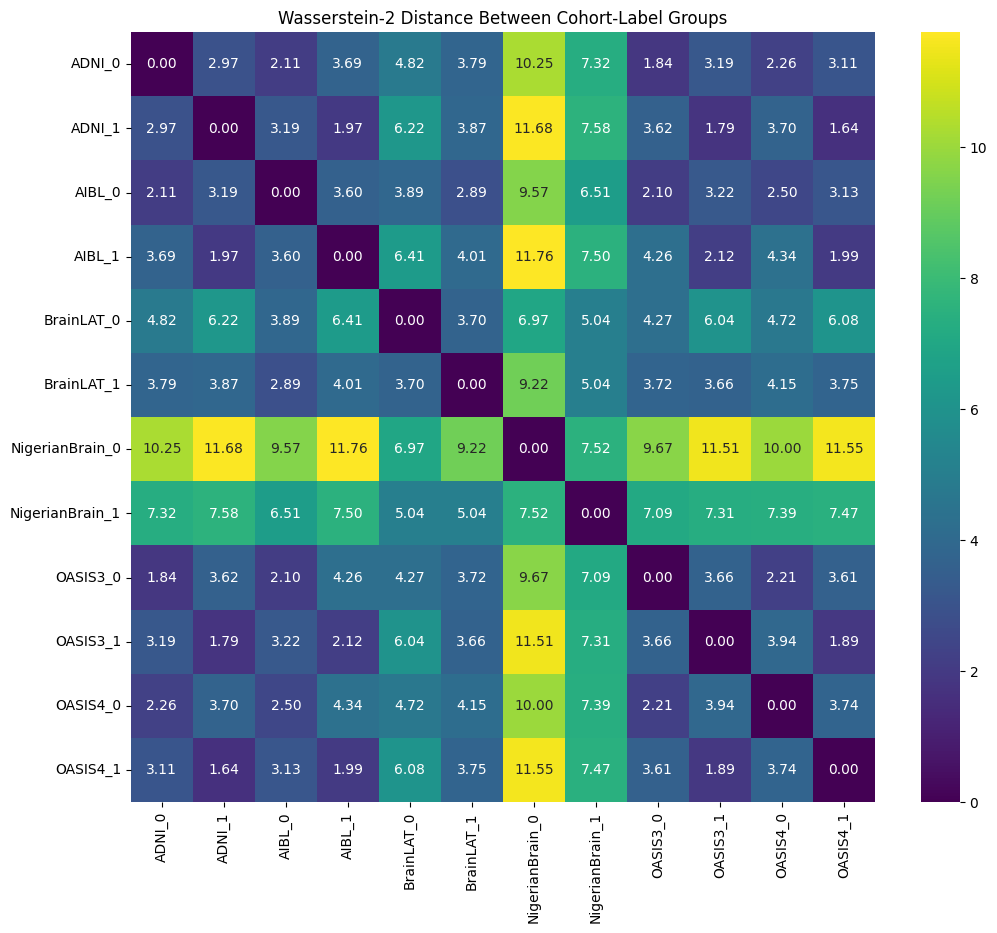

In [15]:
# Suppose 'distance_matrix' is already built with labels like 'ClientA_CN', 'ClientB_AD'

# Get unique (cohort, label) groups
groups = df_feats.groupby(['cohort', 'label'])

group_keys = list(groups.groups.keys())  # list of tuples (cohort, label)

results = []

# Compute Wasserstein-2 distance between all pairs of groups
for (c1, l1), (c2, l2) in itertools.combinations(group_keys, 2):
    X = groups.get_group((c1, l1))[features_cols].to_numpy()
    Y = groups.get_group((c2, l2))[features_cols].to_numpy()
    
    # Uniform weights
    a = np.ones((X.shape[0],)) / X.shape[0]
    b = np.ones((Y.shape[0],)) / Y.shape[0]
    
    # Cost matrix (squared Euclidean)
    M = ot.dist(X, Y, metric='euclidean')**2
    
    # Wasserstein-2 distance
    w2 = np.sqrt(ot.emd2(a, b, M))
    
    results.append({
        'pair': f'{c1}_{l1}-{c2}_{l2}',
        'distance': w2
    })

# Convert to DataFrame and save

# Convert to DataFrame and save
df_results = pd.DataFrame(results)

# Optional: create a heatmap
# Build a square distance matrix
all_keys = [f'{c}_{l}' for c, l in group_keys]
distance_matrix = pd.DataFrame(0, index=all_keys, columns=all_keys, dtype=float)

for row in results:
    g1, g2 = row['pair'].split('-')
    distance_matrix.loc[g1, g2] = row['distance']
    distance_matrix.loc[g2, g1] = row['distance']  # symmetric

plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis')
plt.title('Wasserstein-2 Distance Between Cohort-Label Groups')
plt.show()

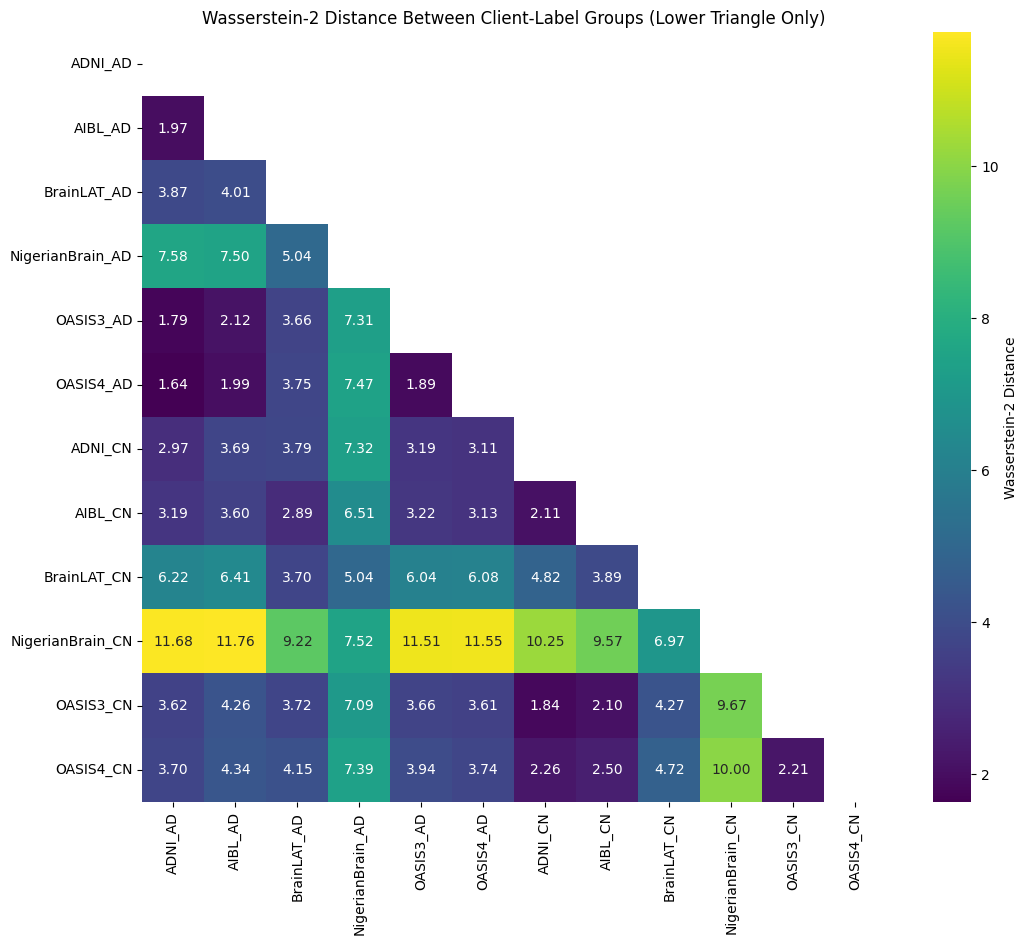

In [16]:
# Map label numbers to class names
label_map = {0: 'CN', 1: 'AD'}

# Build group keys with class names
all_keys = [f'{c}_{label_map[l]}' for c, l in group_keys]

# Order keys: all CN first, then all AD
all_keys_sorted = sorted(all_keys, key=lambda x: x.split('_')[-1])

# Build a square distance matrix
distance_matrix = pd.DataFrame(0, index=all_keys_sorted, columns=all_keys_sorted, dtype=float)

for row in results:
    g1, g2 = row['pair'].split('-')
    # Replace numeric labels with class names
    g1_name = f'{g1.split("_")[0]}_{label_map[int(g1.split("_")[1])]}'
    g2_name = f'{g2.split("_")[0]}_{label_map[int(g2.split("_")[1])]}'
    
    distance_matrix.loc[g1_name, g2_name] = row['distance']
    distance_matrix.loc[g2_name, g1_name] = row['distance']  # symmetric

# Create a mask for the upper triangle
mask = np.triu(np.ones_like(distance_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis',
            mask=mask, cbar_kws={'label': 'Wasserstein-2 Distance'})
plt.title('Wasserstein-2 Distance Between Client-Label Groups (Lower Triangle Only)')
plt.show()

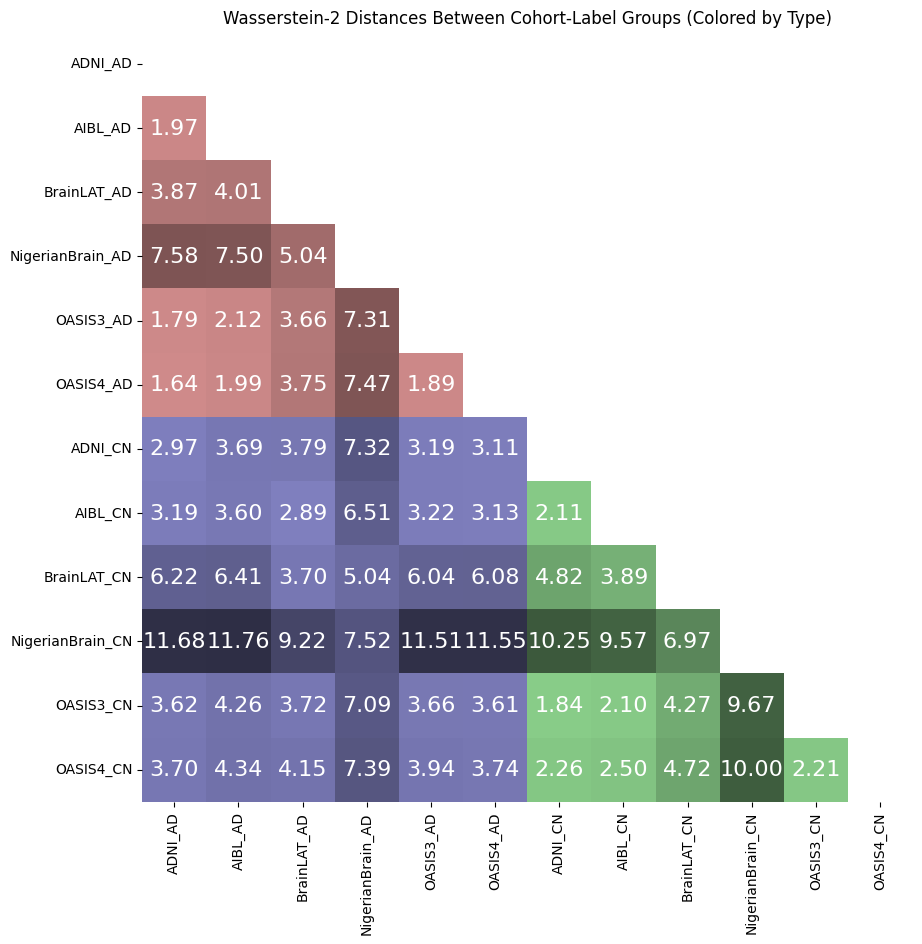

In [18]:
# Suppose 'distance_matrix' is already built with labels like 'ClientA_CN', 'ClientB_AD'
labels = distance_matrix.index.tolist()

# Extract class names from group keys
classes = [lbl.split('_')[-1] for lbl in labels]

# Create a color matrix
color_matrix = np.empty(distance_matrix.shape, dtype=object)

# Define base colors for each comparison type
color_map = {
    'CN_CN': np.array([0.6, 0.9, 0.6]),  # light green
    'AD_AD': np.array([0.9, 0.6, 0.6]),  # light red
    'CN_AD': np.array([0.6, 0.6, 0.9])   # light blue
}

# Normalize distances for intensity (0 = min, 1 = max)
dist_min = distance_matrix.values.min()
dist_max = distance_matrix.values.max()
norm_dist = (distance_matrix.values - dist_min) / (dist_max - dist_min + 1e-8)

for i, cls_i in enumerate(classes):
    for j, cls_j in enumerate(classes):
        if cls_i == 'CN' and cls_j == 'CN':
            base_color = color_map['CN_CN']
        elif cls_i == 'AD' and cls_j == 'AD':
            base_color = color_map['AD_AD']
        else:
            base_color = color_map['CN_AD']
      
        # Invert intensity: darker = higher distance
        intensity = 1 - norm_dist[i, j]
        # scale base color
        color_matrix[i, j] = base_color * (0.3 + 0.7 * intensity)

# Mask upper triangle
mask = np.triu(np.ones_like(distance_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", mask=mask,
            cmap=None, cbar=False, square=True,
            linewidths=.5, linecolor='white',
            annot_kws={"color": "white", "size": 16})

# Apply custom colors using facecolors
for i in range(len(labels)):
    for j in range(len(labels)):
        if mask[i,j]:
            continue
        plt.gca().add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color=color_matrix[i, j], lw=0))

plt.xticks(np.arange(len(labels))+0.5, labels, rotation=90)
plt.yticks(np.arange(len(labels))+0.5, labels, rotation=0)
plt.title('Wasserstein-2 Distances Between Cohort-Label Groups (Colored by Type)')
plt.show()

# 3DINO

In [19]:
df_feats = pd.read_csv("../../local/output/combined_data_dino.csv")
# Assume df_feats has 'cohort' column and 'Feature1'..'Feature768'
features_cols = [f'Feature{i}' for i in range(1, 1025)]

# Get unique cohorts
cohorts = df_feats['cohort'].unique()

# Prepare results list
results = []

In [20]:
# Compute OT distance for each pair
for cohort1, cohort2 in itertools.combinations(cohorts, 2):
    print(f'Computing distance between {cohort1} and {cohort2}')
    X = df_feats[df_feats['cohort'] == cohort1][features_cols].to_numpy()
    Y = df_feats[df_feats['cohort'] == cohort2][features_cols].to_numpy()
    
    # Uniform weights
    a = np.ones((X.shape[0],)) / X.shape[0]
    b = np.ones((Y.shape[0],)) / Y.shape[0]
    
    # Cost matrix (squared Euclidean distance)
    M = ot.dist(X, Y, metric='euclidean')**2
    
    # Wasserstein-2 distance
    w2 = np.sqrt(ot.emd2(a, b, M))
    
    results.append({'pair': f'{cohort1}_{cohort2}', 'distance': w2})

Computing distance between ADNI and AIBL
Computing distance between ADNI and OASIS3
Computing distance between ADNI and OASIS4
Computing distance between ADNI and BrainLAT
Computing distance between ADNI and NigerianBrain
Computing distance between AIBL and OASIS3
Computing distance between AIBL and OASIS4
Computing distance between AIBL and BrainLAT
Computing distance between AIBL and NigerianBrain
Computing distance between OASIS3 and OASIS4
Computing distance between OASIS3 and BrainLAT
Computing distance between OASIS3 and NigerianBrain
Computing distance between OASIS4 and BrainLAT
Computing distance between OASIS4 and NigerianBrain
Computing distance between BrainLAT and NigerianBrain


In [21]:
df_results = pd.DataFrame(results)
distance_matrix = pd.DataFrame(0, index=cohorts, columns=cohorts, dtype=float)

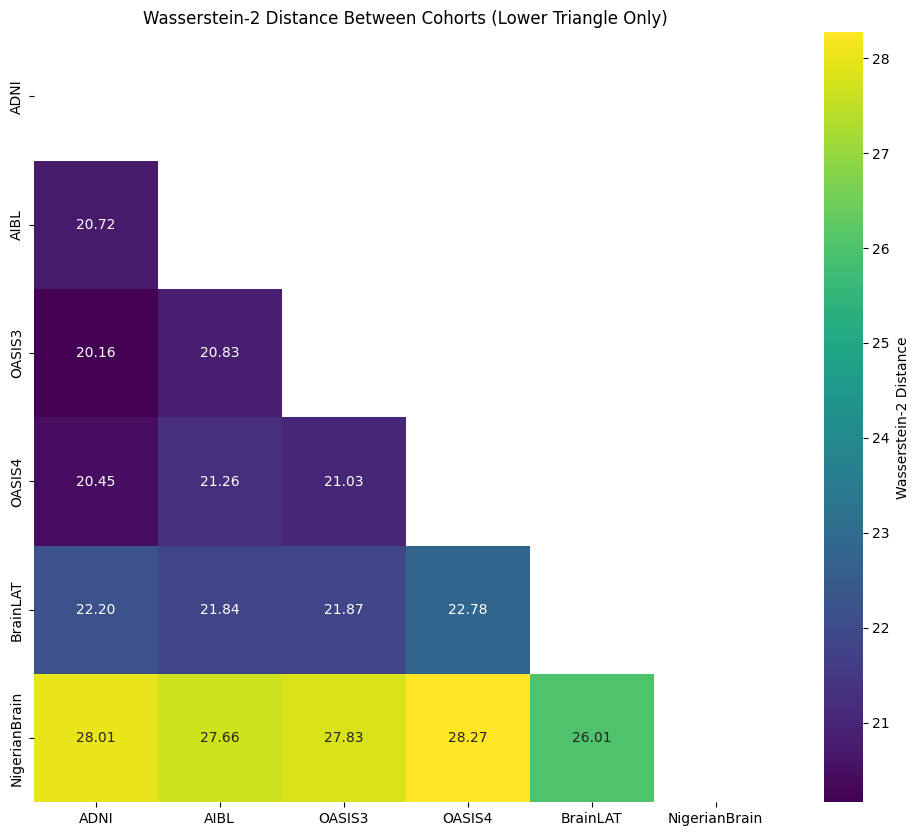

In [22]:
for row in results:
    c1, c2 = row['pair'].split('_')
    distance_matrix.loc[c1, c2] = row['distance']
    distance_matrix.loc[c2, c1] = row['distance']  # symmetric

mask = np.triu(np.ones_like(distance_matrix, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis',
            mask=mask, cbar_kws={'label': 'Wasserstein-2 Distance'})
plt.title('Wasserstein-2 Distance Between Cohorts (Lower Triangle Only)')
plt.show()


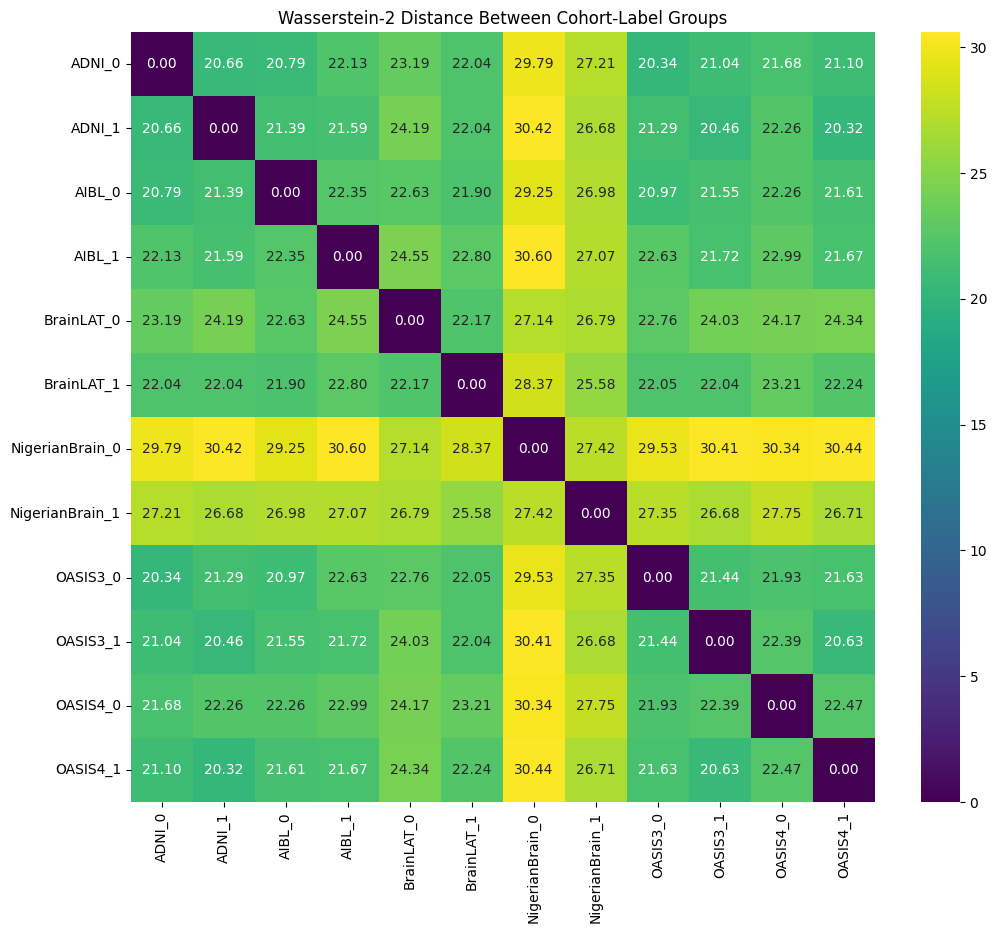

In [23]:
# Suppose 'distance_matrix' is already built with labels like 'ClientA_CN', 'ClientB_AD'

# Get unique (cohort, label) groups
groups = df_feats.groupby(['cohort', 'label'])

group_keys = list(groups.groups.keys())  # list of tuples (cohort, label)

results = []

# Compute Wasserstein-2 distance between all pairs of groups
for (c1, l1), (c2, l2) in itertools.combinations(group_keys, 2):
    X = groups.get_group((c1, l1))[features_cols].to_numpy()
    Y = groups.get_group((c2, l2))[features_cols].to_numpy()
    
    # Uniform weights
    a = np.ones((X.shape[0],)) / X.shape[0]
    b = np.ones((Y.shape[0],)) / Y.shape[0]
    
    # Cost matrix (squared Euclidean)
    M = ot.dist(X, Y, metric='euclidean')**2
    
    # Wasserstein-2 distance
    w2 = np.sqrt(ot.emd2(a, b, M))
    
    results.append({
        'pair': f'{c1}_{l1}-{c2}_{l2}',
        'distance': w2
    })

# Convert to DataFrame and save

# Convert to DataFrame and save
df_results = pd.DataFrame(results)

# Optional: create a heatmap
# Build a square distance matrix
all_keys = [f'{c}_{l}' for c, l in group_keys]
distance_matrix = pd.DataFrame(0, index=all_keys, columns=all_keys, dtype=float)

for row in results:
    g1, g2 = row['pair'].split('-')
    distance_matrix.loc[g1, g2] = row['distance']
    distance_matrix.loc[g2, g1] = row['distance']  # symmetric

plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis')
plt.title('Wasserstein-2 Distance Between Cohort-Label Groups')
plt.show()

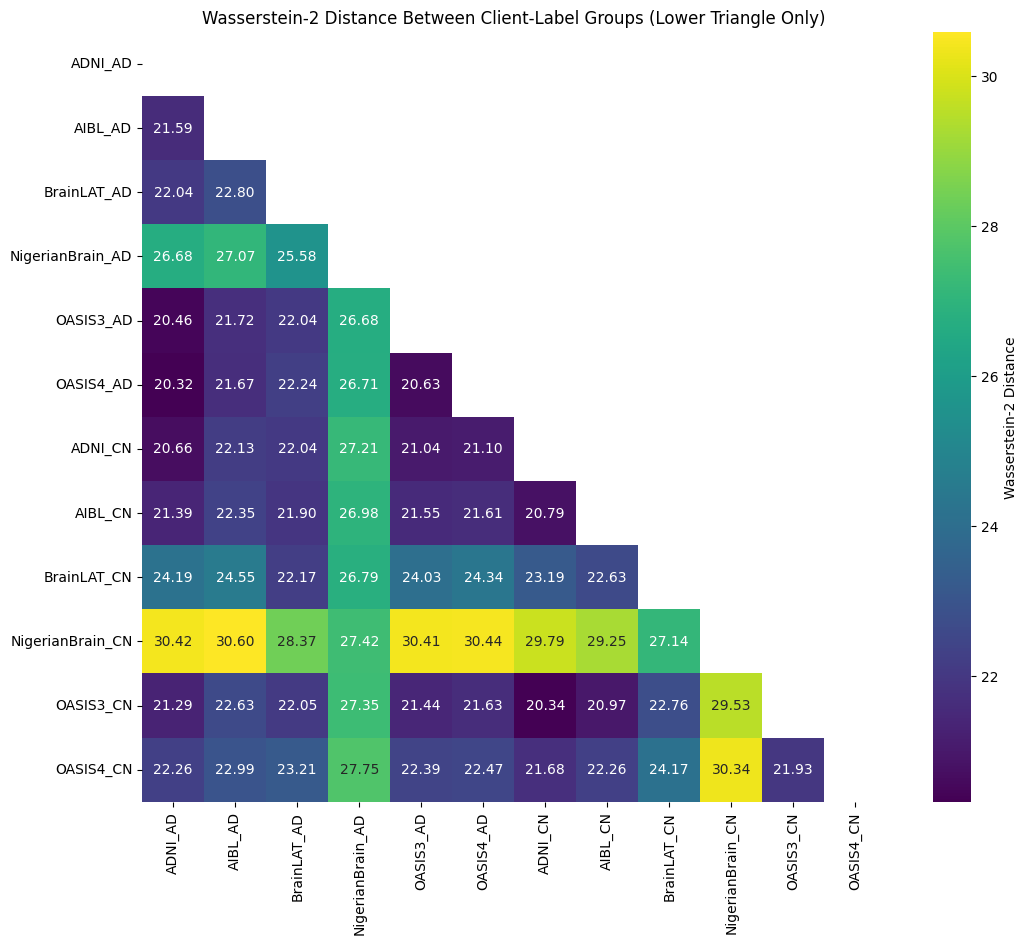

In [24]:
# Map label numbers to class names
label_map = {0: 'CN', 1: 'AD'}

# Build group keys with class names
all_keys = [f'{c}_{label_map[l]}' for c, l in group_keys]

# Order keys: all CN first, then all AD
all_keys_sorted = sorted(all_keys, key=lambda x: x.split('_')[-1])

# Build a square distance matrix
distance_matrix = pd.DataFrame(0, index=all_keys_sorted, columns=all_keys_sorted, dtype=float)

for row in results:
    g1, g2 = row['pair'].split('-')
    # Replace numeric labels with class names
    g1_name = f'{g1.split("_")[0]}_{label_map[int(g1.split("_")[1])]}'
    g2_name = f'{g2.split("_")[0]}_{label_map[int(g2.split("_")[1])]}'
    
    distance_matrix.loc[g1_name, g2_name] = row['distance']
    distance_matrix.loc[g2_name, g1_name] = row['distance']  # symmetric

# Create a mask for the upper triangle
mask = np.triu(np.ones_like(distance_matrix, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", cmap='viridis',
            mask=mask, cbar_kws={'label': 'Wasserstein-2 Distance'})
plt.title('Wasserstein-2 Distance Between Client-Label Groups (Lower Triangle Only)')
plt.show()

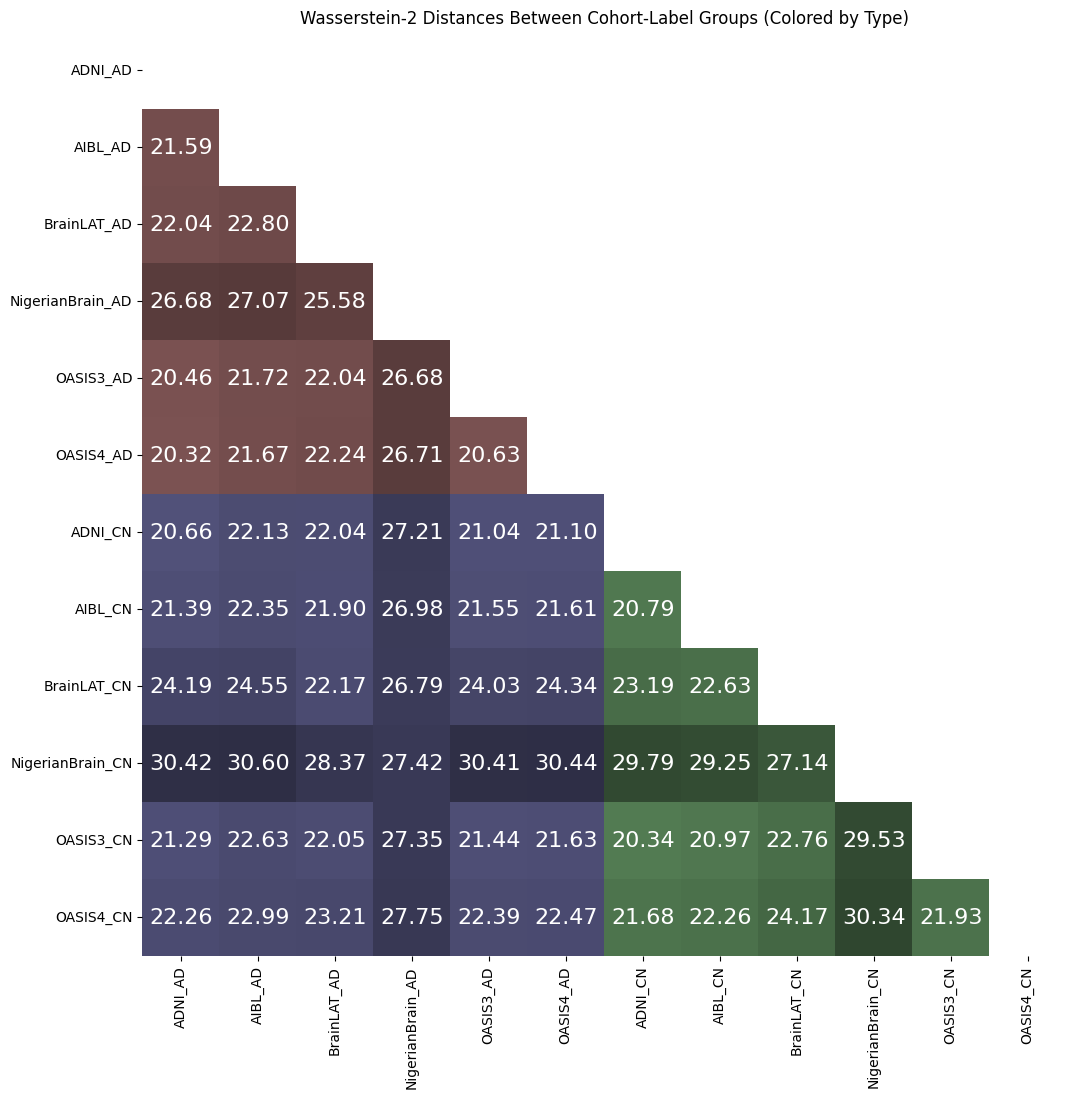

In [26]:
# Suppose 'distance_matrix' is already built with labels like 'ClientA_CN', 'ClientB_AD'
labels = distance_matrix.index.tolist()

# Extract class names from group keys
classes = [lbl.split('_')[-1] for lbl in labels]

# Create a color matrix
color_matrix = np.empty(distance_matrix.shape, dtype=object)

# Define base colors for each comparison type
color_map = {
    'CN_CN': np.array([0.6, 0.9, 0.6]),  # light green
    'AD_AD': np.array([0.9, 0.6, 0.6]),  # light red
    'CN_AD': np.array([0.6, 0.6, 0.9])   # light blue
}

# Normalize distances for intensity (0 = min, 1 = max)
dist_min = distance_matrix.values.min()
dist_max = distance_matrix.values.max()
norm_dist = (distance_matrix.values - dist_min) / (dist_max - dist_min + 1e-8)

for i, cls_i in enumerate(classes):
    for j, cls_j in enumerate(classes):
        if cls_i == 'CN' and cls_j == 'CN':
            base_color = color_map['CN_CN']
        elif cls_i == 'AD' and cls_j == 'AD':
            base_color = color_map['AD_AD']
        else:
            base_color = color_map['CN_AD']
      
        # Invert intensity: darker = higher distance
        intensity = 1 - norm_dist[i, j]
        # scale base color
        color_matrix[i, j] = base_color * (0.3 + 0.7 * intensity)

# Mask upper triangle
mask = np.triu(np.ones_like(distance_matrix, dtype=bool))

plt.figure(figsize=(16, 12))
sns.heatmap(distance_matrix, annot=True, fmt=".2f", mask=mask,
            cmap=None, cbar=False, square=True,
            linewidths=.5, linecolor='white',
            annot_kws={"color": "white", "size": 16})

# Apply custom colors using facecolors
for i in range(len(labels)):
    for j in range(len(labels)):
        if mask[i,j]:
            continue
        plt.gca().add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color=color_matrix[i, j], lw=0))

plt.xticks(np.arange(len(labels))+0.5, labels, rotation=90)
plt.yticks(np.arange(len(labels))+0.5, labels, rotation=0)
plt.title('Wasserstein-2 Distances Between Cohort-Label Groups (Colored by Type)')
plt.show()